# 03 · Asking price, vehicle age, and odometer

## Goal
Describe the asking-price distribution, examine extreme prices, and measure associations with age and mileage in the [Kaggle snapshot](../DATA.md).

## Snapshot findings
The median asking price is **USD 15,000** (middle 50%: USD 7,000–27,590). Rank correlations with asking price are **−0.627 for age** and **−0.559 for mileage** in their main cohorts. Pearson correlations on raw price are near zero but become negative after excluding the flagged price tails; the largest reported prices strongly affect the scale of the raw-price analysis.

## Setup
Run notebook 02 first. The public charts use grouped counts; summaries and correlations use all eligible pairs.

In [1]:
from pathlib import Path
import sys

root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src" / "listings.py").is_file()), None)
if root is None:
    raise RuntimeError("Start Jupyter from the repository or its notebooks directory.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from IPython.display import display

%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.ticker import StrMethodFormatter
import numpy as np
import pandas as pd
from src.listings import PROCESSED, LOW_PRICE_REVIEW, HIGH_PRICE_REVIEW, MILEAGE_REVIEW

path = root / PROCESSED
if not path.is_file():
    raise FileNotFoundError("Run 02_clean_and_derive.ipynb first.")
listings = pd.read_csv(path)
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.axisbelow": True,
                     "grid.alpha": .25, "font.size": 10})
blue = "#235d85"
tick_number = StrMethodFormatter("{x:,.0f}")
price = listings["price"]
assert price.gt(0).all()


## Price distribution
The first chart shows prices up through the 99th percentile. The second includes all positive prices and uses equal log spacing between bin edges.

Median: USD 15,000 | IQR: USD 20,590


,USD
count,3.939850e+05
mean,8.147763e+04
std,1.268064e+07
min,1.000000e+00
1%,1.500000e+02
25%,7.000000e+03
50%,1.500000e+04
75%,2.759000e+04
95%,4.499900e+04
99%,6.874748e+04


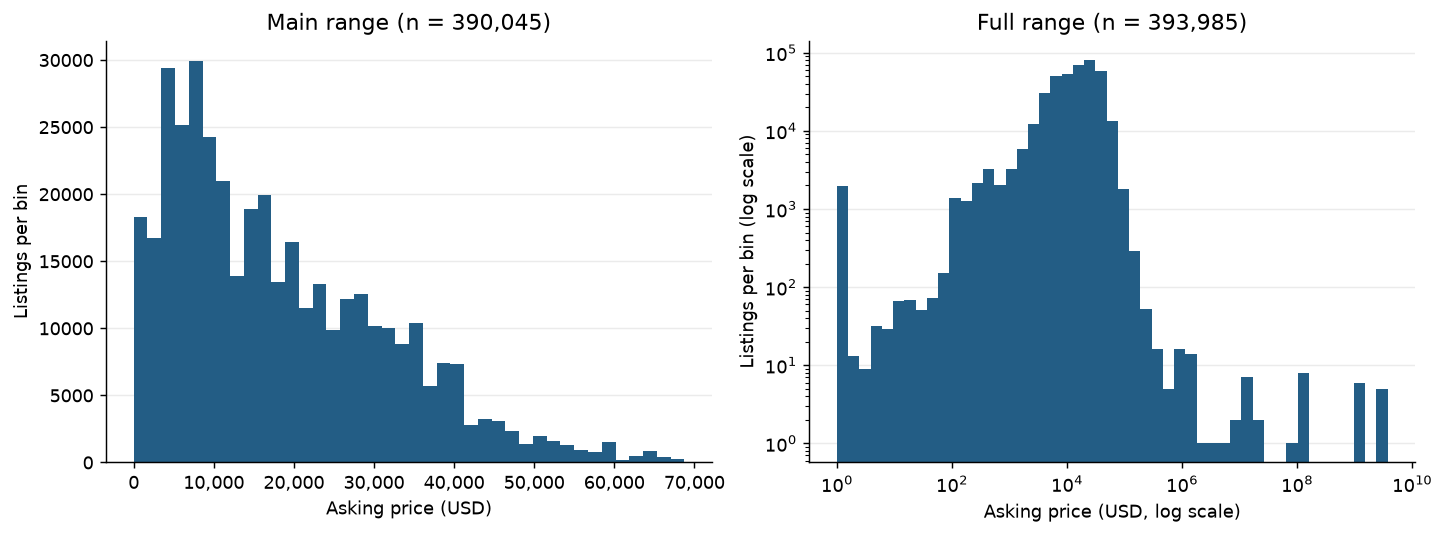

In [2]:
print(f"Median: USD {price.median():,.0f} | IQR: USD {price.quantile(.75) - price.quantile(.25):,.0f}")
display(price.describe(percentiles=[.01, .25, .5, .75, .95, .99]).round(2).to_frame("USD"))

central = price[price.le(price.quantile(.99))]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
axes[0].hist(central, bins=40, color=blue)
axes[0].set(title=f"Main range (n = {len(central):,})",
            xlabel="Asking price (USD)", ylabel="Listings per bin")
axes[0].xaxis.set_major_formatter(tick_number)
log_bins = np.geomspace(price.min(), max(price.max(), price.min() * 1.01), 50)
axes[1].hist(price, bins=log_bins, color=blue)
axes[1].set(title=f"Full range (n = {len(price):,})", xscale="log", yscale="log",
            xlabel="Asking price (USD, log scale)", ylabel="Listings per bin (log scale)")
for ax in axes:
    ax.grid(axis="y")
plt.show()


## Review the price tails
Repeated low prices may be placeholders. An unusual asking price alone does not establish an error.

In [3]:
price_band = np.select(
    [listings["low_price_review"], listings["high_price_review"]],
    [f"Below USD {LOW_PRICE_REVIEW:,}", f"Above USD {HIGH_PRICE_REVIEW:,}"],
    default="Between review thresholds",
)
tail = listings.assign(price_band=price_band).groupby("price_band")["price"]
summary = tail.agg(listings="size", min_usd="min", median_usd="median", max_usd="max")
summary["pct_all_positive"] = (100 * summary["listings"] / len(listings)).round(3)
summary["most_common_usd"] = tail.agg(lambda x: x.value_counts().index[0])
summary["pct_at_most_common"] = tail.agg(lambda x: round(100 * x.value_counts().iloc[0] / len(x), 2))
display(summary)


,listings,min_usd,median_usd,max_usd,pct_all_positive,most_common_usd,pct_at_most_common
price_band,,,,,,,
"Above USD 150,000",196,152995.0,242497.0,3.736929e+09,0.050,163540.0,6.63
Below USD 500,9199,1.0,199.0,4.990000e+02,2.335,1.0,21.21
Between review thresholds,384590,500.0,15900.0,1.500000e+05,97.615,6995.0,0.82


## Age and mileage relationships

Use model year if fewer than half of valid model-year records have usable age. For the main mileage cohort, set aside readings above the review threshold and compare with all nonnegative readings below.

The charts show counts in bins, with no individual points. They focus on the price band between the review thresholds and the central 99% of age and mileage values within that price band. Cells with fewer than 20 listings are hidden. Correlations in the next section use all eligible pairs, including values outside the visible range.

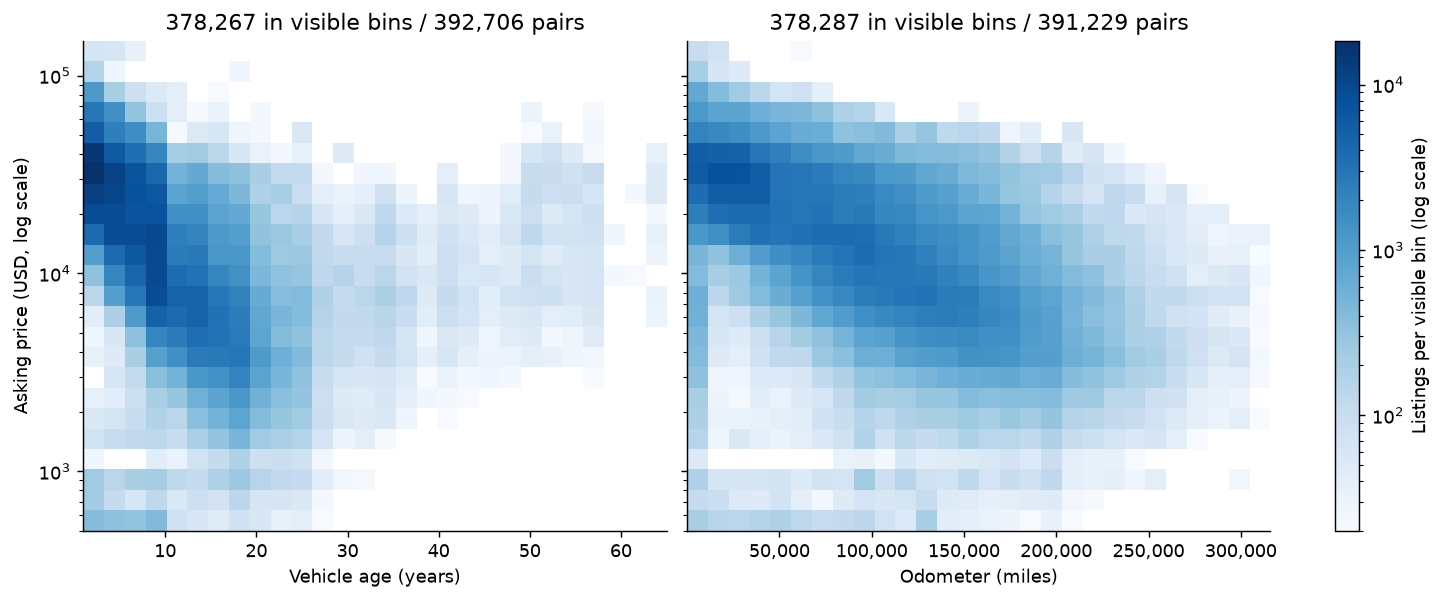

In [4]:
age_field, age_label = "vehicle_age", "Vehicle age (years)"
if listings["vehicle_age"].notna().sum() < listings["model_year"].notna().sum() * .5:
    age_field, age_label = "model_year", "Model year"
    print("Using model year because valid age coverage is below 50%.")

def pairs(frame, field):
    return frame[[field, "price"]].dropna()

mileage = listings.loc[~listings["odometer_review"]]
age_pairs, mileage_pairs = pairs(listings, age_field), pairs(mileage, "odometer")
min_cell_count = 20
price_bins = np.geomspace(LOW_PRICE_REVIEW, HIGH_PRICE_REVIEW, 25)
panels = []
for pair, field, label in [
    (age_pairs, age_field, age_label),
    (mileage_pairs, "odometer", "Odometer (miles)"),
]:
    within = pair.loc[pair["price"].between(LOW_PRICE_REVIEW, HIGH_PRICE_REVIEW)]
    if within.empty:
        panels.append((label, None, None, len(pair), 0))
        continue
    lo, hi = within[field].quantile([.005, .995])
    if hi <= lo:
        lo, hi = lo - .5, hi + .5
    x_edges = np.linspace(lo, hi, 29)
    counts, _, _ = np.histogram2d(within[field], within["price"], bins=[x_edges, price_bins])
    visible = int(counts[counts >= min_cell_count].sum())
    panels.append((label, x_edges, counts, len(pair), visible))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained", sharey=True)
norm = LogNorm(vmin=min_cell_count, vmax=max(
    [min_cell_count + 1, *(p[2].max() for p in panels if p[2] is not None)]
))
mesh = None
for ax, (label, edges, counts, pairs_count, visible) in zip(axes, panels):
    if visible == 0:
        ax.text(.5, .5, "No bins reach 20 listings", ha="center", transform=ax.transAxes)
    else:
        grouped = np.ma.masked_less(counts.T, min_cell_count)
        mesh = ax.pcolormesh(edges, price_bins, grouped, cmap="Blues", norm=norm, shading="auto")
    ax.set(title=f"{visible:,} in visible bins / {pairs_count:,} pairs", xlabel=label,
           yscale="log", ylim=(LOW_PRICE_REVIEW, HIGH_PRICE_REVIEW))
axes[0].set_ylabel("Asking price (USD, log scale)")
axes[1].xaxis.set_major_formatter(tick_number)
if mesh is not None:
    fig.colorbar(mesh, ax=axes, label="Listings per visible bin (log scale)")
plt.show()


## Compare correlations with and without flagged records
The sensitivity cohort excludes both flagged price tails. Spearman correlation is computed by applying Pearson correlation to ranks.

In [5]:
def correlation(pair, field):
    x, y = pair[field], pair["price"]
    varies = x.nunique() > 1 and y.nunique() > 1
    return {"pairs": len(pair),
            "pearson_r": x.corr(y) if varies else np.nan,
            "spearman_rho": x.rank().corr(y.rank()) if varies else np.nan}

mid = ~(listings["low_price_review"] | listings["high_price_review"])
comparisons = {
    f"{age_label}: all positive prices": correlation(age_pairs, age_field),
    f"{age_label}: excluding price flags": correlation(pairs(listings.loc[mid], age_field), age_field),
    f"Mileage: up to {MILEAGE_REVIEW:,} mi": correlation(mileage_pairs, "odometer"),
    "Mileage: all nonnegative readings": correlation(pairs(listings, "odometer"), "odometer"),
    "Mileage: excluding price and mileage flags": correlation(
        pairs(listings.loc[mid & ~listings["odometer_review"]], "odometer"), "odometer"
    ),
}
display(pd.DataFrame.from_dict(comparisons, orient="index").round(3))


,pairs,pearson_r,spearman_rho
Vehicle age (years): all positive prices,392706,0.005,-0.627
Vehicle age (years): excluding price flags,383367,-0.349,-0.669
"Mileage: up to 1,000,000 mi",391229,0.004,-0.559
Mileage: all nonnegative readings,391695,0.011,-0.559
Mileage: excluding price and mileage flags,382050,-0.452,-0.597


## Interpretation
Check the directions and whether the results change with the flagged tails. These are associations in asking prices; seller behavior, vehicle mix, and listing coverage may affect the patterns.